# Handwritten Digit Recognition using CNN
MNIST + Keras. Run every cell in order (Runtime > Run all).

## 1. Install demo library

In [ ]:
!pip install -q gradio

## 2. Load and preprocess MNIST

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Train: (60000, 28, 28) Test: (10000, 28, 28)


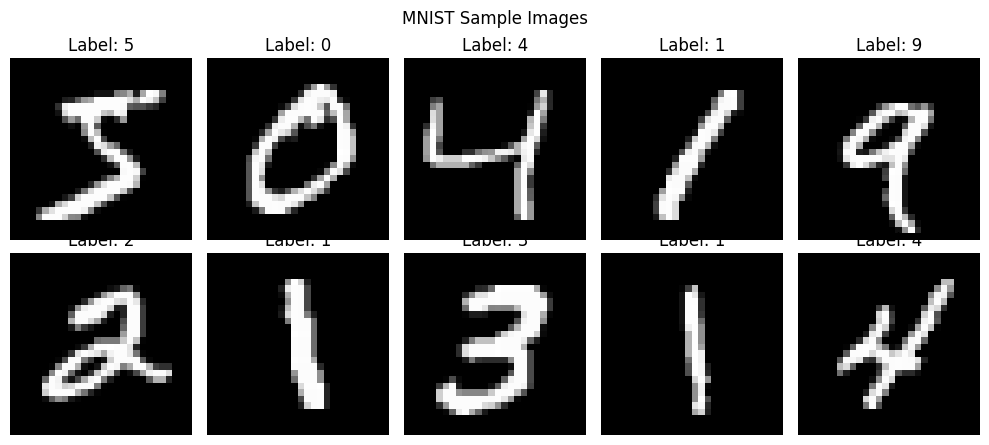

In [ ]:
import numpy as np, matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()
print("Train:", x_train.shape, "Test:", x_test.shape)

# SCREENSHOT 1: sample images from the dataset
fig, ax = plt.subplots(2, 5, figsize=(10, 4.5))
for i, a in enumerate(ax.flat):
    a.imshow(x_train[i], cmap="gray"); a.set_title(f"Label: {y_train[i]}"); a.axis("off")
plt.suptitle("MNIST Sample Images"); plt.tight_layout()
plt.savefig("1_sample_digits.png", dpi=150); plt.show()

x_train = (x_train.astype("float32") / 255.0)[..., None]
x_test  = (x_test.astype("float32") / 255.0)[..., None]

## 3. Build the CNN

In [ ]:
model = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, 3, activation="relu"),
    layers.MaxPooling2D(2),
    layers.Conv2D(64, 3, activation="relu"),
    layers.MaxPooling2D(2),
    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(10, activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()   # SCREENSHOT 2: model summary output

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        16,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,826 (136.04 KB)

 Trainable params: 34,826 (136.04 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Train

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 15s 20ms/step - accuracy: 0.8928 - loss: 0.3559 - val_accuracy: 0.9773 - val_loss: 0.0791
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9660 - loss: 0.1127 - val_accuracy: 0.9827 - val_loss: 0.0629
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9746 - loss: 0.0839 - val_accuracy: 0.9878 - val_loss: 0.0452
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - accuracy: 0.9779 - loss: 0.0714 - val_accuracy: 0.9880 - val_loss: 0.0402
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9812 - loss: 0.0612 - val_accuracy: 0.9897 - val_loss: 0.0381
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9823 - loss: 0.0558 - val_accuracy: 0.9902 - val_loss: 0.0346
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9840 - loss: 0.0507 - val_accuracy: 0.9908 - val_loss: 0.0344
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9852 - loss: 0.0480 - val_accuracy:

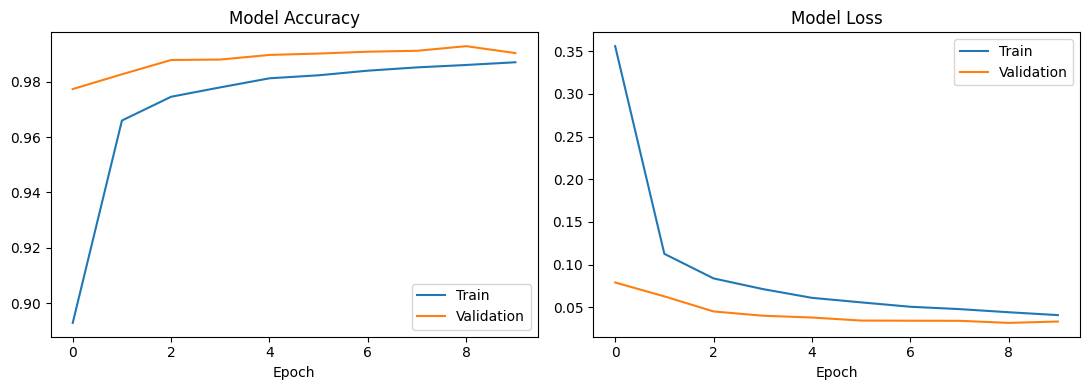

In [ ]:
history = model.fit(x_train, y_train, epochs=10, batch_size=128, validation_split=0.1)

# SCREENSHOT 3: accuracy and loss curves
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(history.history["accuracy"], label="Train"); ax[0].plot(history.history["val_accuracy"], label="Validation")
ax[0].set_title("Model Accuracy"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(history.history["loss"], label="Train"); ax[1].plot(history.history["val_loss"], label="Validation")
ax[1].set_title("Model Loss"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig("3_training_curves.png", dpi=150); plt.show()

## 5. Evaluate

Test accuracy: 99.09%
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


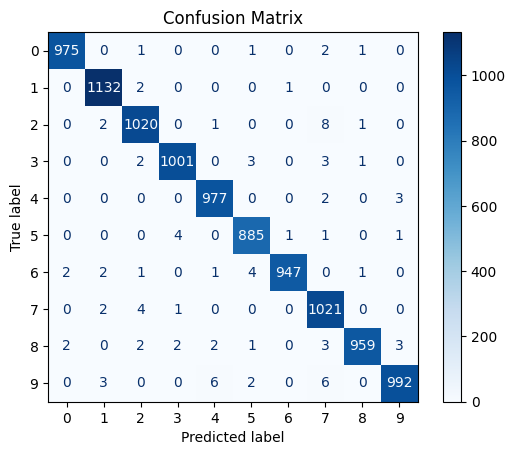

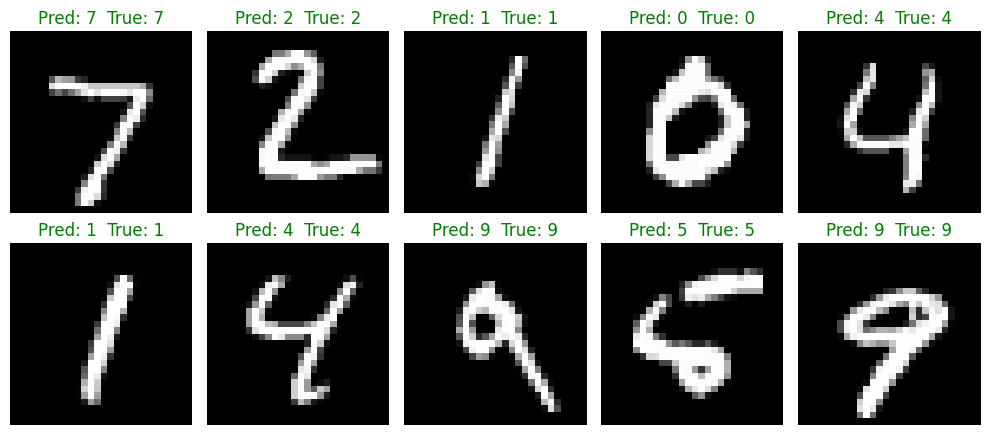

In [ ]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc*100:.2f}%")     # SCREENSHOT 4: this printed line

pred = np.argmax(model.predict(x_test), axis=1)
# SCREENSHOT 5: confusion matrix
ConfusionMatrixDisplay(confusion_matrix(y_test, pred)).plot(cmap="Blues")
plt.title("Confusion Matrix"); plt.savefig("5_confusion_matrix.png", dpi=150); plt.show()

# SCREENSHOT 6: sample predictions
fig, ax = plt.subplots(2, 5, figsize=(10, 4.5))
for i, a in enumerate(ax.flat):
    a.imshow(x_test[i].squeeze(), cmap="gray"); a.axis("off")
    a.set_title(f"Pred: {pred[i]}  True: {y_test[i]}", color="green" if pred[i] == y_test[i] else "red")
plt.tight_layout(); plt.savefig("6_sample_predictions.png", dpi=150); plt.show()

model.save("digit_cnn.keras")

## 6. Demo: draw or upload a digit  (SCREENSHOTS 7 and 8)

In [ ]:
import gradio as gr
from PIL import Image

def predict(img):
    if img is None: return {}
    if isinstance(img, dict):                       # newer Gradio sketchpad returns a dict
        img = img.get("composite", img)
    img = Image.fromarray(np.array(img).astype("uint8")).convert("L").resize((28, 28))
    arr = np.array(img).astype("float32")
    if arr.mean() > 127: arr = 255 - arr            # MNIST = white digit on black background
    arr = arr / 255.0
    probs = model.predict(arr.reshape(1, 28, 28, 1), verbose=0)[0]
    return {str(i): float(probs[i]) for i in range(10)}

draw = gr.Interface(predict, gr.Sketchpad(image_mode="L", type="numpy"), gr.Label(num_top_classes=3), title="Draw a digit")
upload = gr.Interface(predict, gr.Image(type="numpy", image_mode="L"), gr.Label(num_top_classes=3), title="Upload a digit image")
gr.TabbedInterface([draw, upload], ["Draw", "Upload"]).launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://0369b4e2213b9e7758.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


ERROR:    Exception in ASGI application
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/uvicorn/protocols/http/httptools_impl.py", line 422, in run_asgi
    result = await app(  # type: ignore[func-returns-value]
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
        self.scope, self.receive, self.send
        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
    )
    ^
  File "/usr/local/lib/python3.13/dist-packages/uvicorn/middleware/proxy_headers.py", line 63, in __call__
    return await self.app(scope, receive, send)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/fastapi/applications.py", line 1163, in __call__
    await super().__call__(scope, receive, send)
  File "/usr/local/lib/python3.13/dist-packages/starlette/applications.py", line 96, in __call__
    await self.middleware_stack(scope, receive, send)
  File "/usr/local/lib/python3.13/dist-packages/starlette/middleware/errors.py", line 186, i